In [1]:
from google.colab import files
uploaded = files.upload()

Saving books_dataset (1).csv to books_dataset (1).csv


In [2]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset uploaded successfully!
Shape: (1000, 5)


,Title,Price,Rating,Availability,Book_URL
0,A Light in the Attic,51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [3]:
# 1. Check rows and columns
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and non-missing values
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Check book price summary
print("\nPrice summary:")
print(df["Price"].describe())

Dataset shape: (1000, 5)

Column names:
['Title', 'Price', 'Rating', 'Availability', 'Book_URL']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   object 
 3   Availability  1000 non-null   object 
 4   Book_URL      1000 non-null   object 
dtypes: float64(1), object(4)
memory usage: 39.2+ KB

Missing values:
Title           0
Price           0
Rating          0
Availability    0
Book_URL        0
dtype: int64

Duplicate rows: 0

Price summary:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64


In [4]:
# Question 1: What is the average book price?
print("Average book price:", round(df["Price"].mean(), 2))

# Question 2: What is the median book price?
print("Median book price:", round(df["Price"].median(), 2))

# Question 3: What is the cheapest book price?
print("Cheapest book price:", df["Price"].min())

# Question 4: What is the most expensive book price?
print("Most expensive book price:", df["Price"].max())

# Question 5: How many books belong to each rating?
print("\nBooks by rating:")
print(df["Rating"].value_counts().reindex(
    ["One", "Two", "Three", "Four", "Five"], fill_value=0
))

# Question 6: What is the availability of books?
print("\nBook availability:")
print(df["Availability"].value_counts())

Average book price: 35.07
Median book price: 35.98
Cheapest book price: 10.0
Most expensive book price: 59.99

Books by rating:
Rating
One      226
Two      196
Three    203
Four     179
Five     196
Name: count, dtype: int64

Book availability:
Availability
In stock    1000
Name: count, dtype: int64


In [5]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Show all column names
print("\nColumn names:")
print(df.columns)

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (1000, 5)

Column names:
Index(['Title', 'Price', 'Rating', 'Availability', 'Book_URL'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   object 
 3   Availability  1000 non-null   object 
 4   Book_URL      1000 non-null   object 
dtypes: float64(1), object(4)
memory usage: 39.2+ KB

Missing values:
Title           0
Price           0
Rating          0
Availability    0
Book_URL        0
dtype: int64

Duplicate rows: 0


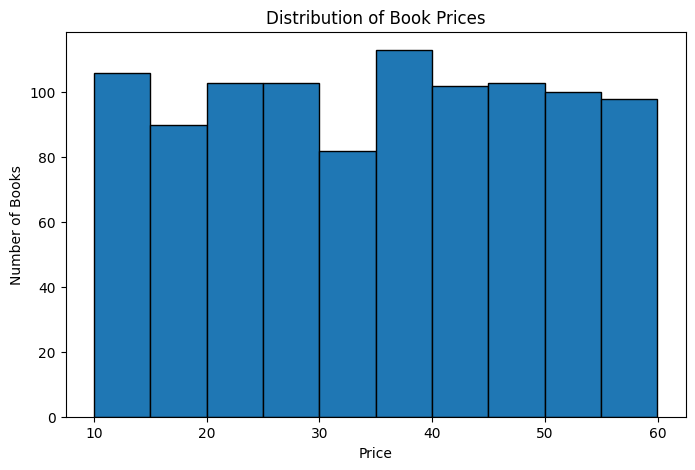

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=10, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price")
plt.ylabel("Number of Books")
plt.show()


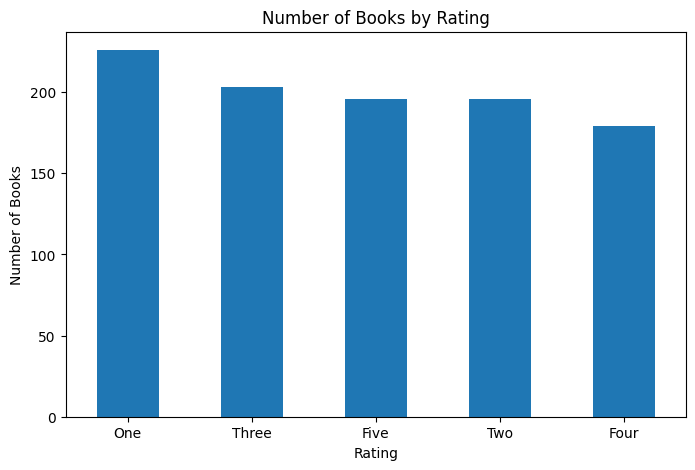

In [7]:

rating_counts = df["Rating"].value_counts()

rating_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Number of Books by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.show()


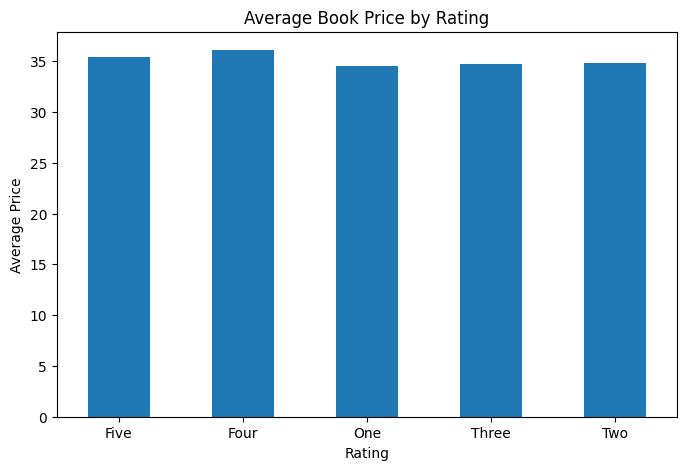

In [9]:

avg_price = df.groupby("Rating")["Price"].mean()

avg_price.plot(kind="bar", figsize=(8, 5))
plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()


In [10]:

from scipy.stats import f_oneway

ratings = ["One", "Two", "Three", "Four", "Five"]

groups = [
    df.loc[df["Rating"] == rating, "Price"]
    for rating in ratings
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference found.")
else:
    print("No statistically significant difference found.")


F-statistic: 0.36594095586137154
P-value: 0.832971014715649
No statistically significant difference found.


In [11]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nPrice data type:")
print(df["Price"].dtype)

print("\nUnique availability values:")
print(df["Availability"].value_counts())

print("\nDuplicate book URLs:")
print(df["Book_URL"].duplicated().sum())

print("\nPrice range:")
print(df["Price"].min(), df["Price"].max())


Missing values:
Title           0
Price           0
Rating          0
Availability    0
Book_URL        0
dtype: int64

Duplicate rows:
0

Price data type:
float64

Unique availability values:
Availability
In stock    1000
Name: count, dtype: int64

Duplicate book URLs:
0

Price range:
10.0 59.99


In [12]:

# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Check summary statistics
print("\nSummary statistics:")
print(df.describe(include="all"))


Dataset shape: (1000, 5)

Column names:
['Title', 'Price', 'Rating', 'Availability', 'Book_URL']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   object 
 3   Availability  1000 non-null   object 
 4   Book_URL      1000 non-null   object 
dtypes: float64(1), object(4)
memory usage: 39.2+ KB

Missing values:
Title           0
Price           0
Rating          0
Availability    0
Book_URL        0
dtype: int64

Duplicate rows: 0

Summary statistics:
                         Title       Price Rating Availability  \
count                     1000  1000.00000   1000         1000   
unique                     999         NaN      5            1   
top     The Star-Touched Queen         NaN    One     In stock  

In [13]:
### Step 2: Data Structure and Variables

The dataset contains 1,000 rows and 5 columns: Title, Price, Rating, Availability, and Book_URL. The Price column contains decimal values, while the other columns contain text data. There are no missing values or duplicate rows. Therefore, the dataset is structurally clean based on these checks.

SyntaxError: invalid syntax (542232122.py, line 3)

 Step 2: Data Structure and Variables

The dataset contains 1,000 rows and 5 columns: Title, Price, Rating, Availability, and Book_URL. The Price column contains decimal values, while the other columns contain text data. There are no missing values or duplicate rows. Therefore, the dataset is structurally clean based on these checks.

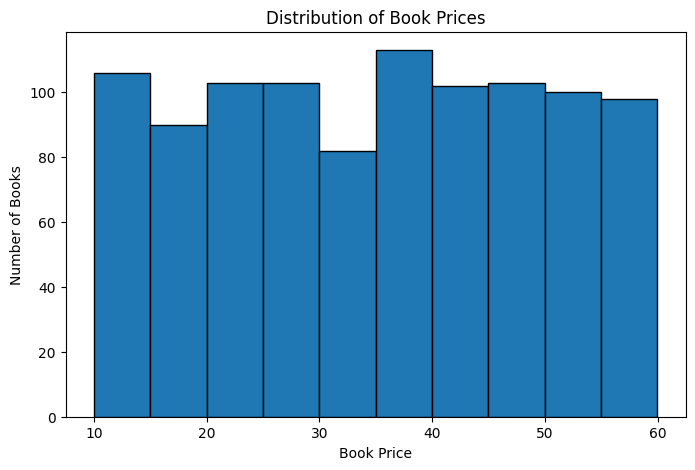

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=10, edgecolor="black")

plt.title("Distribution of Book Prices")
plt.xlabel("Book Price")
plt.ylabel("Number of Books")

plt.show()


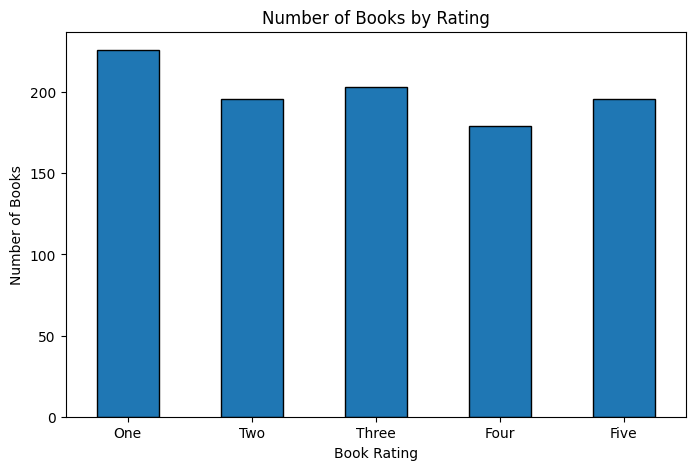

In [17]:

rating_counts = df["Rating"].value_counts()
rating_counts = rating_counts.reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

rating_counts.plot(kind="bar", figsize=(8, 5), edgecolor="black")

plt.title("Number of Books by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)

plt.show()


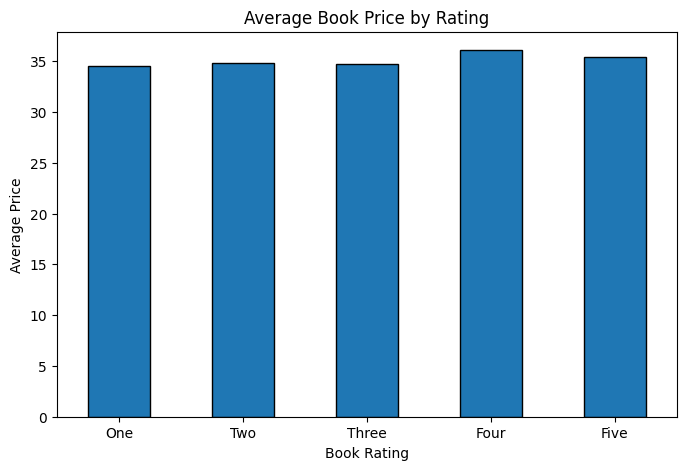

Rating
One      34.561195
Two      34.810918
Three    34.692020
Four     36.093296
Five     35.374490
Name: Price, dtype: float64


In [18]:

avg_price = df.groupby("Rating")["Price"].mean()

avg_price = avg_price.reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

avg_price.plot(kind="bar", figsize=(8, 5), edgecolor="black")

plt.title("Average Book Price by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Average Price")
plt.xticks(rotation=0)

plt.show()

print(avg_price)


 Step 3: Trends, Patterns, and Anomalies

The dataset contains books priced between 10.00 and 59.99, with an average price of 35.07. One-star books are the most common rating category, with 226 books, while four-star books are the least common, with 179 books. All 1,000 books are marked as in stock. The charts help visualize price distribution and rating patterns.

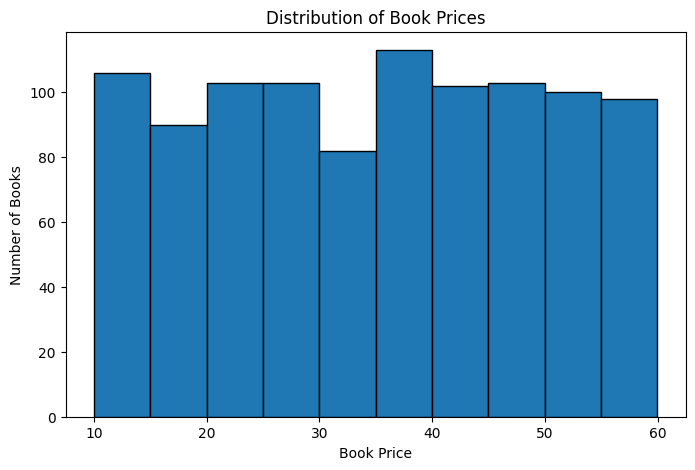

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=10, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Book Price")
plt.ylabel("Number of Books")
plt.show()


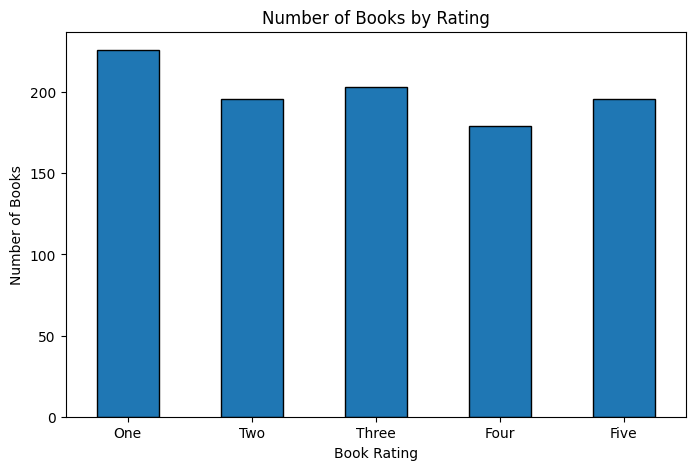

In [20]:

rating_counts = df["Rating"].value_counts()

rating_counts = rating_counts.reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

rating_counts.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Number of Books by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.show()


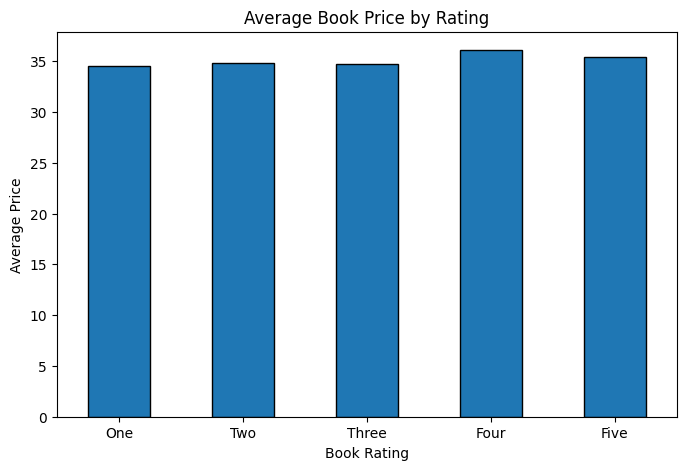

Rating
One      34.561195
Two      34.810918
Three    34.692020
Four     36.093296
Five     35.374490
Name: Price, dtype: float64


In [21]:

avg_price = df.groupby("Rating")["Price"].mean()

avg_price = avg_price.reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

avg_price.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Average Book Price by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()

print(avg_price)


In [22]:
print("Zero or negative prices:", (df["Price"] <= 0).sum())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Zero or negative prices: 0
Missing values: 0
Duplicate rows: 0


In [15]:
# Step 2: Data Structure and Variables
# The dataset contains 1,000 rows and 5 columns.
# The Price column contains decimal values.
# The other columns contain text data.
# There are no missing values or duplicate rows.